# Computer Vision Lab Mid: HOG vs SIFT on Blood-Cell Images
**Registration number:** FA23-BAI-055

## Setup and Personal Settings

In [1]:
!pip install -q medmnist opencv-python scikit-image

In [2]:
# ---- Personal settings (registration number 055) ----
REG_NO    = "055"
SEED      = 55          # last two digits
HOG_CELL  = (16, 16)    # last digit 5 is odd  -> 16 x 16
SIFT_GRID = 6           # last digit 5 is in 5-9 -> 6 x 6 grid (36 keypoints)

# ---- Fixed settings ----
CLASS_IDS   = [1, 5, 6, 7]
CLASS_NAMES = ["eosinophil", "monocyte", "neutrophil", "platelet"]
N_TRAIN, N_VAL, N_TEST = 100, 30, 30
IMG_SIZE    = 128
ROT_ANGLE   = 20
NOISE_SIGMA = 0.05
C_GRID      = [0.1, 1, 10]

import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from medmnist import BloodMNIST
from skimage.feature import hog
from skimage import exposure
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

np.random.seed(SEED)
print("Seed:", SEED, "| HOG cell:", HOG_CELL, "| SIFT grid:", SIFT_GRID, "x", SIFT_GRID)

Seed: 55 | HOG cell: (16, 16) | SIFT grid: 6 x 6


# Q1. Data Setup

In [3]:
# Load the official splits (images are 64 x 64 RGB)
raw = {s: BloodMNIST(split=s, download=True, size=64) for s in ["train", "val", "test"]}

def sample_split(ds, n_per_class, seed):
    """Keep only our 4 classes and pick n_per_class random images from each, using the seed."""
    rng = np.random.RandomState(seed)
    labels = ds.labels.ravel()
    X, y = [], []
    for new_label, cid in enumerate(CLASS_IDS):
        idx = np.where(labels == cid)[0]
        chosen = rng.choice(idx, n_per_class, replace=False)
        X.append(ds.imgs[chosen])
        y += [new_label] * n_per_class
    return np.concatenate(X), np.array(y)

X_train_rgb, y_train = sample_split(raw["train"], N_TRAIN, SEED)
X_val_rgb,   y_val   = sample_split(raw["val"],   N_VAL,   SEED)
X_test_rgb,  y_test  = sample_split(raw["test"],  N_TEST,  SEED)

for name, X, y in [("train", X_train_rgb, y_train), ("val", X_val_rgb, y_val), ("test", X_test_rgb, y_test)]:
    counts = {CLASS_NAMES[k]: int((y == k).sum()) for k in range(4)}
    print(f"{name:5s} | images shape: {X.shape} | labels shape: {y.shape} | class counts: {counts}")

100%|██████████| 156M/156M [00:56<00:00, 2.76MB/s]


train | images shape: (400, 64, 64, 3) | labels shape: (400,) | class counts: {'eosinophil': 100, 'monocyte': 100, 'neutrophil': 100, 'platelet': 100}
val   | images shape: (120, 64, 64, 3) | labels shape: (120,) | class counts: {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}
test  | images shape: (120, 64, 64, 3) | labels shape: (120,) | class counts: {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}


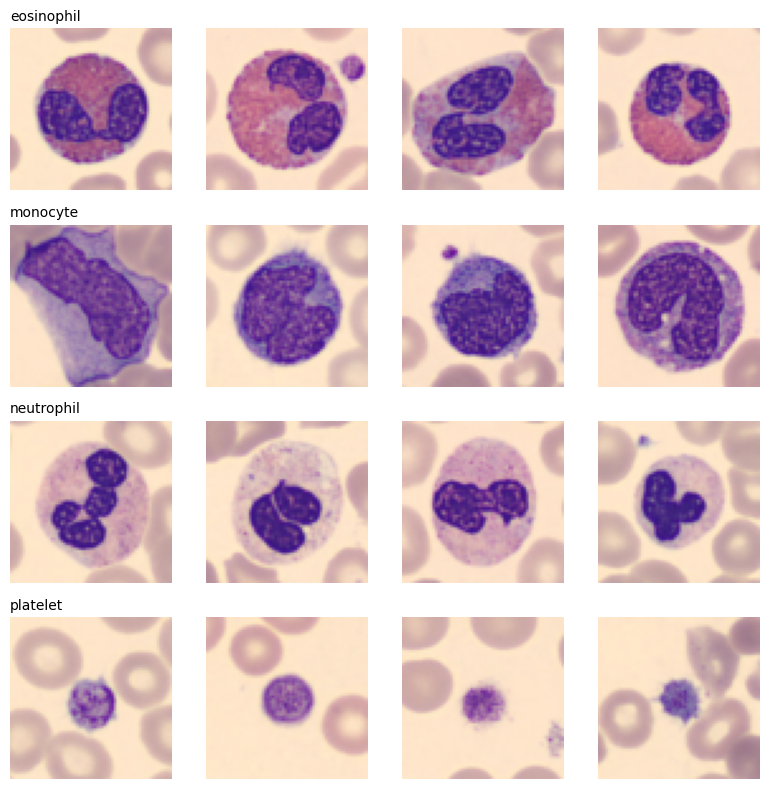

In [4]:
# Grid: 4 example images per class (rows = classes)
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for r in range(4):
    idx = np.where(y_train == r)[0][:4]
    for c in range(4):
        axes[r, c].imshow(X_train_rgb[idx[c]])
        axes[r, c].axis("off")
        if c == 0:
            axes[r, c].set_title(CLASS_NAMES[r], fontsize=10, loc="left")
plt.tight_layout()
plt.show()

In [5]:
# Image preparation: grayscale + resize to 128 x 128 (uint8, 0-255)
def prep(img_rgb):
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    return cv2.resize(gray, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)

X_train = np.array([prep(i) for i in X_train_rgb])
X_val   = np.array([prep(i) for i in X_val_rgb])
X_test  = np.array([prep(i) for i in X_test_rgb])
print("Prepared shapes:", X_train.shape, X_val.shape, X_test.shape, "| dtype:", X_train.dtype)

Prepared shapes: (400, 128, 128) (120, 128, 128) (120, 128, 128) | dtype: uint8


## Helper functions (used by Q2, Q3, Q4)

In [6]:
def make_model(C):
    # Scaler is fitted on training features only; LinearSVC is the required classifier
    return make_pipeline(StandardScaler(), LinearSVC(C=C, max_iter=20000, random_state=SEED))

def choose_C_and_train(F_train, y_train, F_val, y_val):
    """Try each C, train on train, score on VALIDATION, keep the best."""
    best = None
    for C in C_GRID:
        model = make_model(C).fit(F_train, y_train)
        acc = accuracy_score(y_val, model.predict(F_val))
        print(f"C = {C:<5} -> validation accuracy = {acc:.4f}")
        if best is None or acc > best[0]:
            best = (acc, C, model)
    print("Best C:", best[1])
    return best[2], best[1]

def report(model, F_val, y_val, title):
    pred = model.predict(F_val)
    acc = accuracy_score(y_val, pred)
    f1 = f1_score(y_val, pred, average="macro")
    cm = confusion_matrix(y_val, pred)
    print(f"{title} | validation accuracy = {acc:.4f} | macro-F1 = {f1:.4f}")
    print("Confusion matrix (rows = true, cols = predicted):")
    print(cm)
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(cmap="Blues", xticks_rotation=45)
    plt.title(title + " - validation")
    plt.show()
    return cm

# Q2. HOG + SVM

In [7]:
def hog_features(img):
    return hog(img, orientations=9, pixels_per_cell=HOG_CELL, cells_per_block=(2, 2),
               block_norm="L2-Hys", feature_vector=True)

H_train = np.array([hog_features(i) for i in X_train])
H_val   = np.array([hog_features(i) for i in X_val])
print("HOG feature length per image:", H_train.shape[1])
print("HOG matrices:", H_train.shape, H_val.shape)

HOG feature length per image: 1764
HOG matrices: (400, 1764) (120, 1764)


### Hand calculation of the HOG feature length
*(Write your own calculation here: cells per side, blocks per side, values per block, total.)*

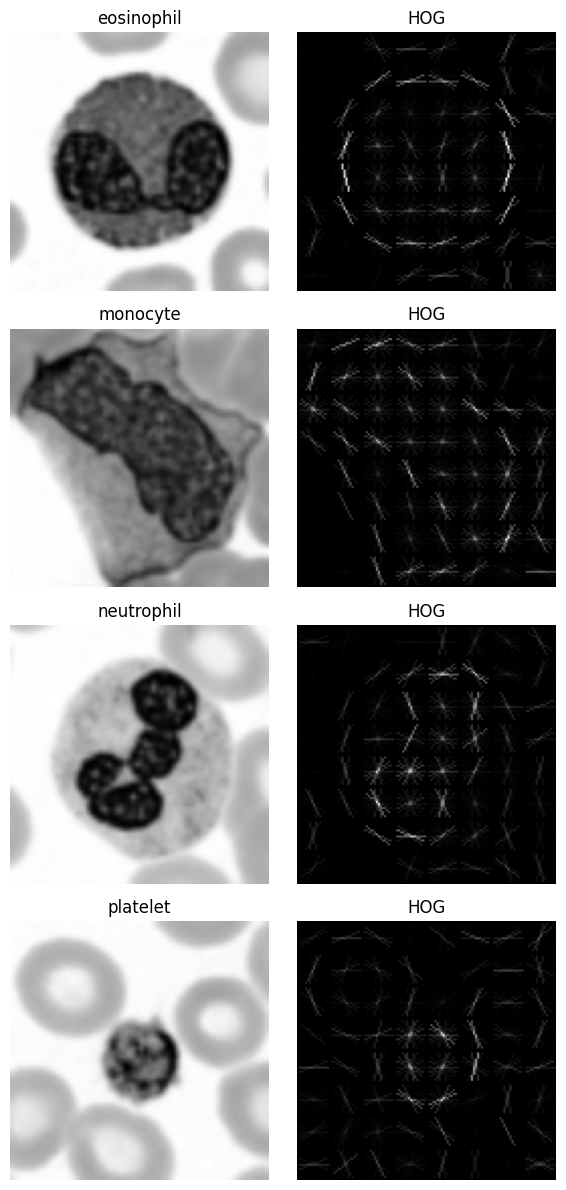

In [8]:
# One HOG picture per class
fig, axes = plt.subplots(4, 2, figsize=(6, 12))
for k in range(4):
    img = X_train[np.where(y_train == k)[0][0]]
    _, hog_img = hog(img, orientations=9, pixels_per_cell=HOG_CELL, cells_per_block=(2, 2),
                     block_norm="L2-Hys", visualize=True)
    hog_img = exposure.rescale_intensity(hog_img, in_range=(0, hog_img.max() + 1e-8))
    axes[k, 0].imshow(img, cmap="gray"); axes[k, 0].set_title(CLASS_NAMES[k]); axes[k, 0].axis("off")
    axes[k, 1].imshow(hog_img, cmap="gray"); axes[k, 1].set_title("HOG"); axes[k, 1].axis("off")
plt.tight_layout()
plt.show()

C = 0.1   -> validation accuracy = 0.6833
C = 1     -> validation accuracy = 0.6833
C = 10    -> validation accuracy = 0.6833
Best C: 0.1
HOG + SVM | validation accuracy = 0.6833 | macro-F1 = 0.6855
Confusion matrix (rows = true, cols = predicted):
[[14  9  7  0]
 [ 8 19  3  0]
 [ 8  2 20  0]
 [ 1  0  0 29]]


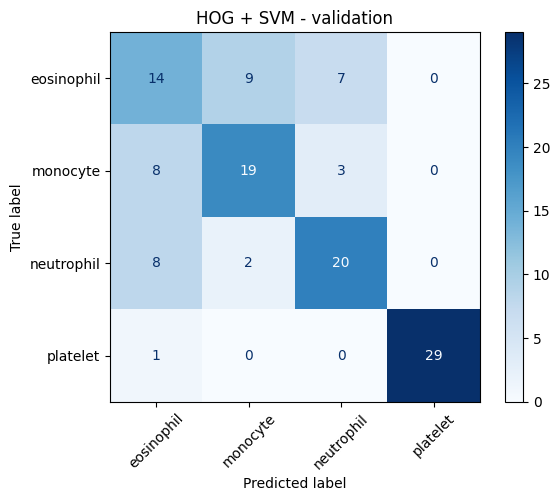

In [9]:
hog_model, hog_C = choose_C_and_train(H_train, y_train, H_val, y_val)
cm_hog = report(hog_model, H_val, y_val, "HOG + SVM")

# Q3. SIFT + SVM

### Part 1: Normal SIFT detection

In [10]:
sift = cv2.SIFT_create()

kp_counts = []
for img in X_train:
    kps, desc = sift.detectAndCompute(img, None)
    kp_counts.append(len(kps))
kp_counts = np.array(kp_counts)

print(f"Average keypoints per image: {kp_counts.mean():.2f}")
print(f"Minimum: {kp_counts.min()} | Maximum: {kp_counts.max()}")
print("Images with zero keypoints:", int((kp_counts == 0).sum()))

Average keypoints per image: 72.52
Minimum: 12 | Maximum: 188
Images with zero keypoints: 0


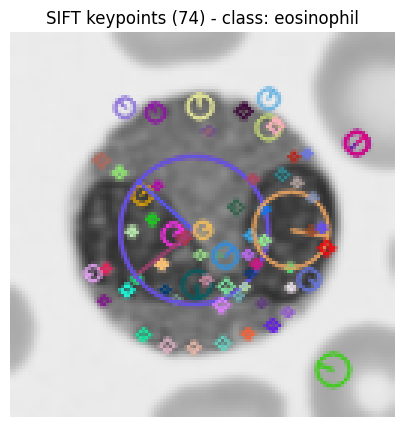

In [11]:
# Draw keypoints on one training image
img = X_train[0]
kps, _ = sift.detectAndCompute(img, None)
vis = cv2.drawKeypoints(img, kps, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.figure(figsize=(5, 5))
plt.imshow(vis, cmap="gray")
plt.title(f"SIFT keypoints ({len(kps)}) - class: {CLASS_NAMES[y_train[0]]}")
plt.axis("off")
plt.show()

**Why is a different number of keypoints per image a problem for an SVM?**
*(Write your one-sentence answer here.)*

### Part 2: Fixed grid of keypoints

In [12]:
def grid_keypoints(grid=SIFT_GRID, size=IMG_SIZE, kp_size=32):
    step = size / grid
    centers = (np.arange(grid) + 0.5) * step      # centre of each grid cell
    return [cv2.KeyPoint(float(x), float(y), kp_size) for y in centers for x in centers]

def sift_features(img):
    kps = grid_keypoints()
    _, desc = sift.compute(img, kps)
    assert desc.shape == (SIFT_GRID * SIFT_GRID, 128), desc.shape
    return desc.flatten()

S_train = np.array([sift_features(i) for i in X_train])
S_val   = np.array([sift_features(i) for i in X_val])
print("Grid points:", SIFT_GRID * SIFT_GRID)
print("SIFT feature length per image:", S_train.shape[1])
print("SIFT matrices:", S_train.shape, S_val.shape)

Grid points: 36
SIFT feature length per image: 4608
SIFT matrices: (400, 4608) (120, 4608)


### Part 3: Train SIFT + SVM

C = 0.1   -> validation accuracy = 0.7000
C = 1     -> validation accuracy = 0.7000
C = 10    -> validation accuracy = 0.7000
Best C: 0.1
SIFT + SVM | validation accuracy = 0.7000 | macro-F1 = 0.6947
Confusion matrix (rows = true, cols = predicted):
[[14  7  8  1]
 [ 5 21  3  1]
 [ 5  2 21  2]
 [ 1  0  1 28]]


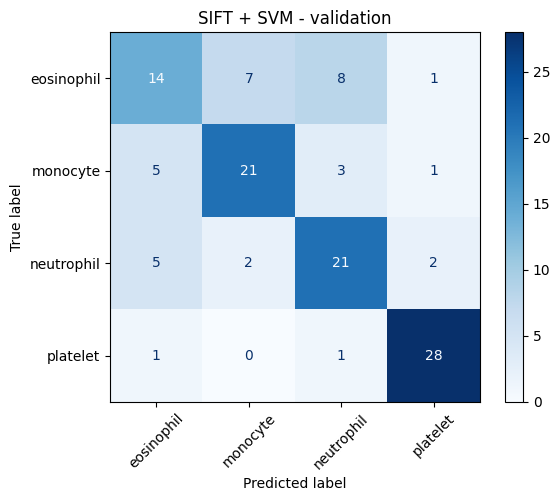

In [13]:
sift_model, sift_C = choose_C_and_train(S_train, y_train, S_val, y_val)
cm_sift = report(sift_model, S_val, y_val, "SIFT + SVM")

# Q4. Robustness

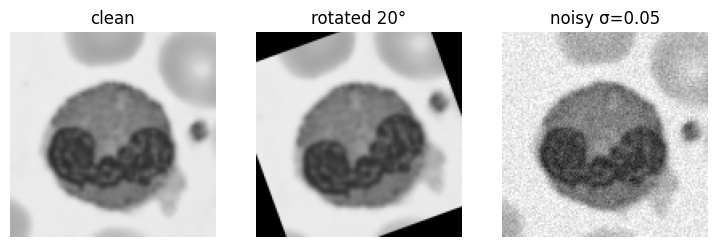

In [14]:
# Transformations are applied to the 128 x 128 grayscale test images BEFORE feature extraction
def rotate(img, angle=ROT_ANGLE):
    M = cv2.getRotationMatrix2D((IMG_SIZE / 2, IMG_SIZE / 2), angle, 1.0)
    return cv2.warpAffine(img, M, (IMG_SIZE, IMG_SIZE), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_CONSTANT, borderValue=0)

def add_noise(img, sigma=NOISE_SIGMA, rng=None):
    x = img.astype(np.float32) / 255.0                  # scale to 0-1
    x = x + rng.normal(0, sigma, x.shape)               # Gaussian noise
    x = np.clip(x, 0, 1)
    return (x * 255).round().astype(np.uint8)           # back to uint8 (SIFT needs it)

rng_noise = np.random.RandomState(SEED)
X_test_rot   = np.array([rotate(i) for i in X_test])
X_test_noisy = np.array([add_noise(i, rng=rng_noise) for i in X_test])

# Quick visual check (one image: clean / rotated / noisy)
fig, ax = plt.subplots(1, 3, figsize=(9, 3))
for a, im, t in zip(ax, [X_test[0], X_test_rot[0], X_test_noisy[0]], ["clean", "rotated 20°", "noisy σ=0.05"]):
    a.imshow(im, cmap="gray", vmin=0, vmax=255); a.set_title(t); a.axis("off")
plt.show()

In [15]:
# Models are frozen: NO re-training, NO re-choosing C. Only predict.
def test_acc(model, extractor, X):
    F = np.array([extractor(i) for i in X])
    return accuracy_score(y_test, model.predict(F))

rows = []
for name, model, extractor in [("HOG + SVM", hog_model, hog_features),
                               ("SIFT + SVM", sift_model, sift_features)]:
    rows.append({
        "Model": name,
        "Clean accuracy":   test_acc(model, extractor, X_test),
        "Rotated accuracy": test_acc(model, extractor, X_test_rot),
        "Noisy accuracy":   test_acc(model, extractor, X_test_noisy),
    })

results = pd.DataFrame(rows).set_index("Model")
print(results.round(4))
print()
print("Drop under rotation:", (results["Clean accuracy"] - results["Rotated accuracy"]).round(4).to_dict())
print("Drop under noise   :", (results["Clean accuracy"] - results["Noisy accuracy"]).round(4).to_dict())

            Clean accuracy  Rotated accuracy  Noisy accuracy
Model                                                       
HOG + SVM           0.7000            0.6167          0.2667
SIFT + SVM          0.6583            0.3167          0.6250

Drop under rotation: {'HOG + SVM': 0.0833, 'SIFT + SVM': 0.3417}
Drop under noise   : {'HOG + SVM': 0.4333, 'SIFT + SVM': 0.0333}


# Q5. Short Answers and AI Log

In [17]:
# Most confused pair of classes (from the VALIDATION confusion matrices, so the test set stays untouched)
def most_confused(cm):
    off = cm.copy().astype(float)
    np.fill_diagonal(off, 0)
    sym = off + off.T                       # count confusion in both directions
    i, j = np.unravel_index(np.triu(sym, 1).argmax(), sym.shape)
    return CLASS_NAMES[i], CLASS_NAMES[j], int(sym[i, j])

print("HOG  most confused pair:", most_confused(cm_hog))
print("SIFT most confused pair:", most_confused(cm_sift))

HOG  most confused pair: ('eosinophil', 'monocyte', 17)
SIFT most confused pair: ('eosinophil', 'neutrophil', 13)
